# NQ Post-Open Rebound After Extreme Overnight Drops

**Research question:** After a *very large* overnight drop, does NQ (Nasdaq-100 futures) rebound between **09:35 and 10:00 New York time**, and is the rebound large enough to cover trading costs?

| | |
|---|---|
| **H₀ (null)** | After large overnight drops, the 09:35→10:00 return is not positive. |
| **H₁ (alternative)** | After sufficiently large overnight drops, the average 09:35→10:00 return is positive. |
| **Trading hypothesis** | A rule using only information available by 09:35 makes money *out of sample*, after costs. |

**Background.** This follows a replication of Iwanaga & Sakemoto (2026), *"Does overnight return predict the first half-hour return for U.S. market indices?"* (SSRN 5807282). On NQ we found that the paper's overnight reversal is real but weak (β×100 = −4.15 vs −9.19 for SPY), happens almost entirely in the first ~5 minutes after 09:30, and is too small to trade. This notebook tests a narrower idea: **only extreme drops, entering at 09:35.**

**How to read this notebook:** every step explains *what* we do and *why*, in plain language. All rules were fixed **before** looking at the validation and test periods.

> ⚠️ **Research, not financial advice.** The out-of-sample result is based on only 18 trades. See *Limitations* at the end.

## 0. Setup
Data comes from the **LSE Terminal** app (`~/.config/lse-terminal/data/`, read-only). Columns: `ts` (Unix seconds, UTC), `open, high, low, close, volume`. The data files are not included in this repository.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import pandas_market_calendars as mcal
import matplotlib.pyplot as plt

DATA = Path.home() / ".config/lse-terminal/data"
NY = "America/New_York"
TICK, POINT_VALUE, COMMISSION_RT = 0.25, 20.0, 4.50     # NQ: 0.25 tick, $20 per point, ~$4.50 round-trip fees
Path("charts").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

def load_bars(tf):
    df = pd.read_csv(DATA / f"NQ_F_{tf}.csv")
    df["ts"] = pd.to_datetime(df["ts"], unit="s", utc=True).dt.tz_convert(NY)
    df = df.set_index("ts").sort_index()
    df = df[~df.index.duplicated(keep="last")]
    px = ["open", "high", "low", "close"]
    df[px] = (df[px] * 4).round() / 4          # snap to the 0.25 tick (removes float noise like 30807.749999)
    return df

b1, b5 = load_bars("1M"), load_bars("5M")
print("1-minute:", b1.index[0], "->", b1.index[-1], f"({len(b1):,} bars)")
print("5-minute:", b5.index[0], "->", b5.index[-1], f"({len(b5):,} bars)")

1-minute: 2020-01-01 18:00:00-05:00 -> 2026-10-12 19:59:00-04:00 (2,383,444 bars)
5-minute: 2016-05-29 18:00:00-04:00 -> 2026-08-26 16:55:00-04:00 (718,616 bars)


## 1. Data validation (before any analysis)

### 1a. Does a timestamp mark the *start* or the *end* of a bar?
This decides whether "the price at 10:00" is honest or secretly uses future data. Two independent checks:
* The opening bell (09:30) causes a huge volume spike. If timestamps are bar **starts**, the spike is on the bar labelled 09:30.
* NQ stops trading daily 17:00–18:00. If timestamps are bar starts, the last bar is 16:59 and the first is 18:00.

In [2]:
x = b1[(b1.index >= "2021-01-01") & (b1.index.dayofweek < 5)]
hm = x.index.strftime("%H:%M")
vol = x.groupby(hm)["volume"].median()
print("Median 1-min volume:", {t: int(vol[t]) for t in ["09:28", "09:29", "09:30", "09:31"]})
present = sorted(set(hm[(hm >= "16:57") & (hm <= "18:02")]))
print("Bars present around the daily break:", present)
assert vol["09:30"] > 3 * vol["09:29"] and "16:59" in present and "17:00" not in present and "18:00" in present
print("=> timestamps are bar START times. 'Price at HH:MM' = CLOSE of the bar that ends at HH:MM.")

Median 1-min volume: {'09:28': 677, '09:29': 835, '09:30': 5020, '09:31': 3627}
Bars present around the daily break: ['16:57', '16:58', '16:59', '18:00', '18:01', '18:02']
=> timestamps are bar START times. 'Price at HH:MM' = CLOSE of the bar that ends at HH:MM.


### 1b. Do the 1-minute and 5-minute files agree?
We use 5-minute data for history (from 2016) and 1-minute data where it is newer. They must give identical prices.

In [3]:
def at(df, step, hhmm, kind):
    # kind='open': first trade at hhmm (OPEN of bar starting hhmm); kind='close': last trade before hhmm
    t = pd.Timestamp(f"2000-01-01 {hhmm}")
    if kind == "close":
        t -= pd.Timedelta(minutes=step)
    s = df[df.index.strftime("%H:%M") == t.strftime("%H:%M")][kind]
    s.index = s.index.tz_localize(None).normalize()
    return s

for hhmm, kind in [("09:30", "open"), ("10:00", "close"), ("16:00", "close")]:
    j = pd.concat([at(b1, 1, hhmm, kind), at(b5, 5, hhmm, kind)], axis=1, keys=["m1", "m5"]).dropna()
    print(f"{hhmm} {kind:5s}: {len(j)} overlapping days, identical on {np.mean(j.m1 == j.m5):.2%}")

09:30 open : 1708 overlapping days, identical on 100.00%


10:00 close: 1703 overlapping days, identical on 100.00%


16:00 close: 1652 overlapping days, identical on 100.00%


### 1c. Contract rollovers
A futures "continuous" series is stitched from quarterly contracts. If it is **not back-adjusted**, the switch creates a fake price jump that would look like an overnight move. We look at the price gap on the bar at 00:00 UTC on the Monday of expiry week, versus the same bar one week earlier.

In [4]:
r5 = b1.resample("5min", label="left", closed="left").agg(
    {"open": "first", "high": "max", "low": "min", "close": "last", "volume": "sum"}).dropna()
bars = pd.concat([b5[b5.index < "2026-08-26"], r5[r5.index >= "2026-08-26"]]).sort_index()
gap = (bars.open / bars.close.shift() - 1) * 100
gap.index = gap.index.tz_convert("UTC")

def third_friday(y, m):
    d = pd.Timestamp(y, m, 15); return d + pd.Timedelta(days=(4 - d.dayofweek) % 7)
EXPIRIES = [third_friday(y, m) for y in range(2016, 2027) for m in (3, 6, 9, 12)]
rows = []
for e in EXPIRIES:
    mon = e - pd.Timedelta(days=4)
    k1, k0 = pd.Timestamp(mon.date(), tz="UTC"), pd.Timestamp((mon - pd.Timedelta(days=7)).date(), tz="UTC")
    if k1 in gap.index and k0 in gap.index:
        rows.append((e, gap[k1], gap[k0]))
roll = pd.DataFrame(rows, columns=["expiry", "gap% expiry-week", "gap% week before"]).set_index("expiry")
print(roll.loc["2022-06-01":"2024-10-01"].round(3).to_string())
print(f"\nAverage gap: expiry week {roll.iloc[:,0].mean():+.3f}%  vs  normal week {roll.iloc[:,1].mean():+.3f}%")
print("=> NOT back-adjusted (≈ +1% jumps in 2022-2024). Fix: drop every day from 11 days before each expiry to expiry.")

            gap% expiry-week  gap% week before
expiry                                        
2022-06-17             0.223            -0.010
2022-09-16             0.604            -0.002
2022-12-16             0.990             0.004
2023-03-17             1.011             0.000
2023-06-16             1.222             0.003
2023-09-15             1.287             0.002
2023-12-15             1.299             0.002
2024-03-15             1.372             0.008
2024-06-21             1.325             0.003
2024-09-20             1.219             0.019

Average gap: expiry week +0.350%  vs  normal week +0.001%
=> NOT back-adjusted (≈ +1% jumps in 2022-2024). Fix: drop every day from 11 days before each expiry to expiry.


## 2. Build one row per trading day

Definitions (New York time, regular NYSE session):

| Symbol | Meaning |
|---|---|
| `prev_close` | last trade before 16:00 on the previous NYSE session |
| `open` | first trade at 09:30 |
| `p0935` | last trade before 09:35 (**known at 09:35:00**) |
| `o0935` | first trade at/after 09:35 → **our entry price** |
| `p1000` | last trade before 10:00 → **our exit price** |

Filters: only full NYSE sessions (no half-days) for today and yesterday, every needed bar must exist (no filling gaps with stale prices), and no roll-window days.

In [5]:
P = pd.DataFrame({"open": at(bars, 5, "09:30", "open"), "p0935": at(bars, 5, "09:35", "close"),
                  "o0935": at(bars, 5, "09:35", "open"), "p1000": at(bars, 5, "10:00", "close"),
                  "p1600": at(bars, 5, "16:00", "close")})
P["o0936"] = at(b1, 1, "09:36", "open")                       # 1-min-later entry (robustness, 2020+)

sch = mcal.get_calendar("NYSE").schedule(start_date="2016-05-01", end_date="2026-10-13")
sch.index = pd.DatetimeIndex(sch.index).tz_localize(None).normalize()
close_ny = sch.market_close.dt.tz_convert(NY)
cal = pd.DataFrame({"full": (close_ny.dt.hour == 16) & (close_ny.dt.minute == 0)})
cal["prev_day"], cal["prev_full"] = cal.index.to_series().shift(1), cal.full.shift(1).fillna(False).astype(bool)

d = cal.join(P, how="left")
d["prev_close"] = d.prev_day.map(P.p1600)
d["roll_win"] = False
for e in EXPIRIES:
    d.loc[(d.index >= e - pd.Timedelta(days=11)) & (d.index <= e), "roll_win"] = True
d = d[d.index >= "2016-06-01"]
complete = d[["open", "p0935", "o0935", "p1000", "prev_close"]].notna().all(axis=1)
keep = d.full & d.prev_full & complete & ~d.roll_win
print(f"NYSE sessions: {len(d)} | half-days removed: {int((~(d.full & d.prev_full)).sum())} | "
      f"missing bars: {int((d.full & d.prev_full & ~complete).sum())} | roll-window days: {int((d.full & d.prev_full & complete & d.roll_win).sum())}")
D = d[keep].copy()
print(f"Clean days: {len(D)}  ({D.index[0].date()} -> {D.index[-1].date()})")

NYSE sessions: 2607 | half-days removed: 42 | missing bars: 14 | roll-window days: 407
Clean days: 2144  (2016-06-03 -> 2026-10-09)


## 3. Signal features — using only information known at 09:35

* **Overnight return** `R_ON` = open / prev_close − 1 (in %).
* **Drop size in "normal units"** `z` = `R_ON` ÷ (standard deviation of `R_ON` over the **previous** 60 days). A −1% night is huge in a calm market but normal in a wild one; `z` adjusts for that. Today's value is **never** used in its own volatility.
* **First 5 minutes** `R5` = p0935 / open − 1 — known at 09:35:00, so it may be used for the decision.
* **Outcome** = `o0935 → p1000` in NQ points (long).

In [6]:
D["R_ON"] = (D.open / D.prev_close - 1) * 100
D["sd60"] = D.R_ON.rolling(60, min_periods=40).std().shift(1)
D["z"] = D.R_ON / D.sd60
D["R5"] = (D.p0935 / D.open - 1) * 100
D["gross"] = D.p1000 - D.o0935
D["gross_delay"] = D.p1000 - D.o0936

# leak check: recompute volatility by hand from the 60 days strictly BEFORE each day
for i in np.random.default_rng(0).choice(np.arange(100, len(D)), 25, replace=False):
    assert np.isclose(D.R_ON.iloc[i-60:i].std(), D.sd60.iloc[i])
print("Leak check passed: volatility uses only past days.")
D = D.dropna(subset=["z", "R5", "gross"])
print(f"Days with features: {len(D)}")

Leak check passed: volatility uses only past days.
Days with features: 2104


## 4. Pre-registered design (fixed before testing)

| Item | Choice |
|---|---|
| Candidate rules | `z ≤ −1.0 / −1.5 / −2.0` × first-5-min filter `none / R5>0 / R5<0` → **9 rules**, long only |
| Choose rule using | **TRAIN only** — highest average points, at least 30 trades |
| Periods | **TRAIN** 2016-08 → 2021-12 · **VALIDATE** 2022–2023 · **TEST** 2024 → 2026-10 |
| Costs (per round trip) | slippage per side + $4.50 fees: optimistic 0.5 tick · base 1 tick · stress 2 ticks · extreme 4 ticks |

In [7]:
PERIODS = {"TRAIN": ("2016-06-01", "2021-12-31"), "VALIDATE": ("2022-01-01", "2023-12-31"), "TEST": ("2024-01-01", "2026-12-31")}
COSTS = {k: 2 * s * TICK + COMMISSION_RT / POINT_VALUE for k, s in
         [("optimistic", .5), ("base", 1), ("stress", 2), ("extreme", 4)]}
RULES = {f"z<={t:+.1f} | {f}": (t, f) for t in (-1.0, -1.5, -2.0) for f in ("none", "R5>0", "R5<0")}

def period(df, name):
    a, b = PERIODS[name]; return df.loc[a:b]

def select(df, rule):
    t, f = RULES[rule]
    m = df.z <= t
    if f == "R5>0": m &= df.R5 > 0
    if f == "R5<0": m &= df.R5 < 0
    return df[m]

def summary(points, cost=0.0):
    net = points - cost
    t, p2 = stats.ttest_1samp(net, 0) if len(net) > 1 else (np.nan, np.nan)
    return {"trades": len(net), "avg_pts": net.mean(), "median_pts": net.median(), "t_stat": t,
            "p_one_sided": (p2 / 2 if t > 0 else 1 - p2 / 2) if len(net) > 1 else np.nan,
            "win_%": (net > 0).mean() * 100, "total_$": net.sum() * POINT_VALUE}

print("Costs in points per round trip:", {k: round(v, 3) for k, v in COSTS.items()})
train_tbl = pd.DataFrame({r: summary(select(period(D, "TRAIN"), r).gross) for r in RULES}).T
display(train_tbl.round(2))
eligible = train_tbl[train_tbl.trades >= 30]
FROZEN = eligible.avg_pts.idxmax()
print(f"\nFROZEN RULE (chosen on TRAIN only): {FROZEN}")

Costs in points per round trip: {'optimistic': 0.475, 'base': 0.725, 'stress': 1.225, 'extreme': 2.225}


,trades,avg_pts,median_pts,t_stat,p_one_sided,win_%,total_$
z<=-1.0 | none,127.0,3.41,2.00,1.04,0.15,51.97,8665.0
z<=-1.0 | R5>0,81.0,2.57,2.50,0.79,0.22,55.56,4170.0
z<=-1.0 | R5<0,46.0,4.89,-3.25,0.70,0.24,45.65,4495.0
z<=-1.5 | none,72.0,5.73,-3.00,1.42,0.08,48.61,8250.0
z<=-1.5 | R5>0,51.0,7.43,6.50,2.01,0.02,54.90,7575.0
z<=-1.5 | R5<0,21.0,1.61,-12.00,0.15,0.44,33.33,675.0
z<=-2.0 | none,47.0,8.34,2.25,1.62,0.06,53.19,7840.0
z<=-2.0 | R5>0,38.0,8.61,6.88,2.03,0.03,57.89,6545.0
z<=-2.0 | R5<0,9.0,7.19,-5.75,0.34,0.37,33.33,1295.0



FROZEN RULE (chosen on TRAIN only): z<=-2.0 | R5>0


**Note.** No training rule is strongly significant on its own (best t ≈ 2.0 before costs — borderline). The selected rule is: **overnight drop of at least 2 "normal units" (z ≤ −2) AND NQ already above the 09:30 open at 09:35 → buy at 09:35, sell at 10:00.** Bigger drops looked better in training, and requiring the bounce to have already started filtered out days that kept falling.

## 5. Results of the frozen rule — before and after costs

In [8]:
rows = {}
for name in list(PERIODS) + ["OUT-OF-SAMPLE (VAL+TEST)"]:
    x = select(D.loc["2022-01-01":], FROZEN) if name.startswith("OUT") else select(period(D, name), FROZEN)
    for c in ["gross"] + list(COSTS):
        s = summary(x.gross, 0 if c == "gross" else COSTS[c])
        rows[(name, c)] = s
res = pd.DataFrame(rows).T
res.index.names = ["period", "costs"]
display(res.round(3))

trades  avg_pts  median_pts  t_stat  \
period                   costs                                             
TRAIN                    gross         38.0    8.612       6.875   2.026   
                         optimistic    38.0    8.137       6.400   1.914   
                         base          38.0    7.887       6.150   1.855   
                         stress        38.0    7.387       5.650   1.738   
                         extreme       38.0    6.387       4.650   1.502   
VALIDATE                 gross          8.0   50.000      86.625   1.563   
                         optimistic     8.0   49.525      86.150   1.548   
                         base           8.0   49.275      85.900   1.540   
                         stress         8.0   48.775      85.400   1.524   
                         extreme        8.0   47.775      84.400   1.493   
TEST                     gross         10.0   52.875      29.625   1.891   
                         optimistic    10.0   52.400      29.150   1.874   
                         base          10.0   52.150      28.900   1.865   
                         stress        10.0   51.650      28.400   1.847   
                         extreme       10.0   50.650      27.400   1.811   
OUT-OF-SAMPLE (VAL+TEST) gross         18.0   51.597      53.125   2.525   
                         optimistic    18.0   51.122      52.650   2.502   
                         base          18.0   50.872      52.400   2.490   
                         stress        18.0   50.372      51.900   2.465   
                         extreme       18.0   49.372      50.900   2.416   

                                     p_one_sided   win_%  total_$  
period                   costs                                     
TRAIN                    gross             0.025  57.895   6545.0  
                         optimistic        0.032  57.895   6184.0  
                         base              0.036  57.895   5994.0  
                         stress            0.045  57.895   5614.0  
                         extreme           0.071  55.263   4854.0  
VALIDATE                 gross             0.081  62.500   8000.0  
                         optimistic        0.083  62.500   7924.0  
                         base              0.084  62.500   7884.0  
                         stress            0.086  62.500   7804.0  
                         extreme           0.090  62.500   7644.0  
TEST                     gross             0.046  60.000  10575.0  
                         optimistic        0.047  60.000  10480.0  
                         base              0.048  60.000  10430.0  
                         stress            0.049  60.000  10330.0  
                         extreme           0.052  60.000  10130.0  
OUT-OF-SAMPLE (VAL+TEST) gross             0.011  61.111  18575.0  
                         optimistic        0.011  61.111  18404.0  
                         base              0.012  61.111  18314.0  
                         stress            0.012  61.111  18134.0  
                         extreme           0.014  61.111  17774.0

**Plain-English reading:** in training the rule made about **+8.6 points per trade** (t ≈ 2.0 before costs, borderline). In the two later periods, which were *not* used to choose the rule, it made about **+50 points per trade**. Costs barely matter, because each trade's move (~50 points) is far larger than the cost (0.5–2.2 points).

## 6. Equity curve — training vs validation vs test

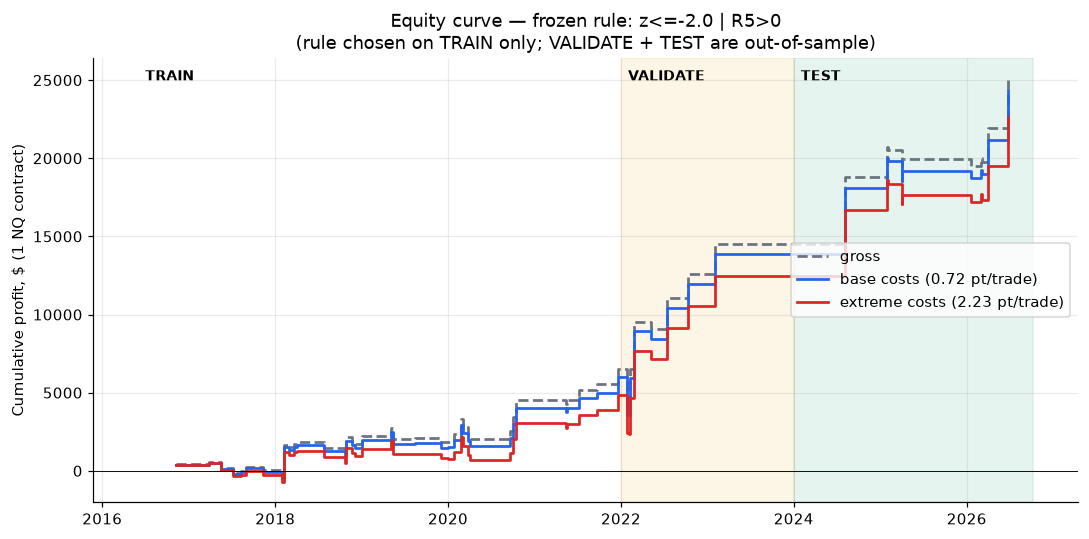

In [9]:
sel = select(D, FROZEN)
fig, ax = plt.subplots(figsize=(10, 5))
for c, col, ls in [("gross", "#6b7280", "--"), ("base", "#2563eb", "-"), ("extreme", "#dc2626", "-")]:
    cost = 0 if c == "gross" else COSTS[c]
    eq = ((sel.gross - cost) * POINT_VALUE).cumsum()
    ax.step(eq.index, eq.values, where="post", color=col, ls=ls, lw=1.8,
            label=f"{c}" + ("" if c == "gross" else f" costs ({cost:.2f} pt/trade)"))
colors = {"TRAIN": "#ffffff", "VALIDATE": "#f59e0b", "TEST": "#059669"}
for n, (a, b) in PERIODS.items():
    ax.axvspan(pd.Timestamp(a), min(pd.Timestamp(b), D.index[-1]), color=colors[n], alpha=.10)
    ax.text(pd.Timestamp(a) + pd.Timedelta(days=30), 0.95, n, transform=ax.get_xaxis_transform(), fontsize=9, weight="bold")
ax.axhline(0, color="k", lw=.6)
ax.set_ylabel("Cumulative profit, $ (1 NQ contract)")
ax.set_title(f"Equity curve — frozen rule: {FROZEN}\n(rule chosen on TRAIN only; VALIDATE + TEST are out-of-sample)")
ax.legend(loc="center right"); fig.tight_layout(); fig.savefig("charts/nb_equity.png"); plt.show()

## 7. Every out-of-sample trade
Small samples can hide a "one lucky day" story, so here is every trade from 2022 onward.

In [10]:
oos = select(D.loc["2022-01-01":], FROZEN)
tbl = pd.DataFrame({"overnight_%": oos.R_ON, "z": oos.z, "first5_%": oos.R5, "entry_0935": oos.o0935,
                    "exit_1000": oos.p1000, "gross_pts": oos.gross, "net_pts_base": oos.gross - COSTS["base"],
                    "net_$_base": (oos.gross - COSTS["base"]) * POINT_VALUE})
tbl.index = tbl.index.date
display(tbl.round(2))

,overnight_%,z,first5_%,entry_0935,exit_1000,gross_pts,net_pts_base,net_$_base
2022-01-25,-1.94,-3.28,0.01,14220.75,14100.25,-120.50,-121.22,-2424.5
2022-02-03,-2.71,-3.74,0.05,14711.25,14710.50,-0.75,-1.48,-29.5
2022-02-10,-2.00,-2.45,0.32,14790.00,14909.50,119.50,118.78,2375.5
2022-02-24,-3.21,-3.57,0.88,13189.50,13340.50,151.00,150.28,3005.5
2022-05-09,-1.92,-2.04,0.19,12474.25,12452.00,-22.25,-22.98,-459.5
2022-07-13,-2.00,-2.07,0.31,11579.75,11679.50,99.75,99.02,1980.5
2022-10-13,-2.90,-3.19,0.17,10540.00,10615.00,75.00,74.28,1485.5
2023-02-03,-2.19,-2.00,0.40,12624.25,12722.50,98.25,97.52,1950.5
2024-08-05,-5.38,-7.50,0.66,17677.00,17889.50,212.50,211.78,4235.5
2025-01-27,-3.58,-5.49,0.54,21237.00,21334.25,97.25,96.52,1930.5


## 8. Robustness checks

In [11]:
net = (oos.gross - COSTS["base"]).sort_values()
rng = np.random.default_rng(1)
boot = [rng.choice(net.values, len(net)).mean() for _ in range(10_000)]
dl = oos.gross_delay.dropna() - COSTS["extreme"]
checks = {
    "Out-of-sample trades": len(net),
    "Average net (base)": f"{net.mean():+.2f} pt",
    "Median net (base)": f"{net.median():+.2f} pt",
    "Without the 1 best trade": f"{net.iloc[:-1].mean():+.2f} pt",
    "Without the 3 best trades": f"{net.iloc[:-3].mean():+.2f} pt",
    "Share of profit from the 3 best trades": f"{net.iloc[-3:].sum() / net.sum() * 100:.0f}%",
    "Bootstrap 95% range of the average": f"{np.percentile(boot, 2.5):+.1f} .. {np.percentile(boot, 97.5):+.1f} pt",
    "Entry 1 minute later + extreme costs": f"{dl.mean():+.2f} pt (n={len(dl)})",
    "Average return in % (scale-free)": f"{(oos.gross / oos.o0935 * 100).mean():+.3f}% per trade",
}
display(pd.Series(checks, name="value").to_frame())

,value
Out-of-sample trades,18
Average net (base),+50.87 pt
Median net (base),+52.40 pt
Without the 1 best trade,+41.41 pt
Without the 3 best trades,+26.38 pt
Share of profit from the 3 best trades,57%
Bootstrap 95% range of the average,+11.6 .. +90.7 pt
Entry 1 minute later + extreme costs,+57.66 pt (n=18)
Average return in % (scale-free),+0.316% per trade


### Does the rebound grow with the size of the drop?
If the effect is real, bigger drops should rebound *more*, step by step. This chart uses all days (all periods, gross).

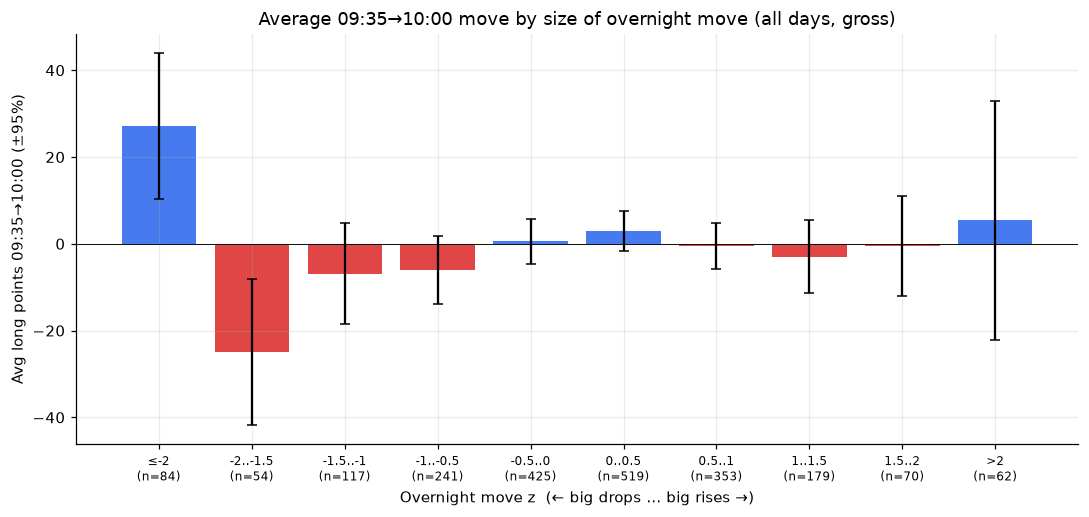

In [12]:
bins = [-np.inf, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, np.inf]
labs = ["≤-2", "-2..-1.5", "-1.5..-1", "-1..-0.5", "-0.5..0", "0..0.5", "0.5..1", "1..1.5", "1.5..2", ">2"]
g = D.assign(b=pd.cut(D.z, bins, labels=labs)).groupby("b", observed=True).gross.agg(["mean", "std", "size"])
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(range(len(g)), g["mean"], yerr=1.96 * g["std"] / np.sqrt(g["size"]), capsize=3,
       color=["#2563eb" if v > 0 else "#dc2626" for v in g["mean"]], alpha=.85)
ax.axhline(0, color="k", lw=.6)
ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(g.index, g["size"])], fontsize=8)
ax.set_xlabel("Overnight move z  (← big drops … big rises →)"); ax.set_ylabel("Avg long points 09:35→10:00 (±95%)")
ax.set_title("Average 09:35→10:00 move by size of overnight move (all days, gross)")
fig.tight_layout(); fig.savefig("charts/nb_buckets.png"); plt.show()

⚠️ **Honest warning from this chart:** the strongest drops (z ≤ −2) rebound, but the next group (−2 to −1.5) *falls*. A clean real effect would grow smoothly with drop size. This non-monotonic pattern is a sign the result may partly be **small-sample luck**.

## 9. Transparency: all 9 rules in every period (shown after freezing)

In [13]:
allp = pd.DataFrame({r: {f"{p} n": len(x := select(period(D, p), r)) for p in PERIODS} |
                        {f"{p} avg pts": x2.gross.mean() for p in PERIODS for x2 in [select(period(D, p), r)]}
                     for r in RULES}).T
display(allp[[f"{p} {k}" for p in PERIODS for k in ("n", "avg pts")]].round(2))

,TRAIN n,TRAIN avg pts,VALIDATE n,VALIDATE avg pts,TEST n,TEST avg pts
z<=-1.0 | none,127.0,3.41,62.0,-9.73,66.0,4.56
z<=-1.0 | R5>0,81.0,2.57,37.0,7.18,32.0,-11.51
z<=-1.0 | R5<0,46.0,4.89,25.0,-34.75,34.0,19.68
z<=-1.5 | none,72.0,5.73,26.0,-16.53,40.0,23.84
z<=-1.5 | R5>0,51.0,7.43,16.0,7.16,19.0,3.33
z<=-1.5 | R5<0,21.0,1.61,10.0,-54.42,21.0,42.40
z<=-2.0 | none,47.0,8.34,11.0,25.52,26.0,61.90
z<=-2.0 | R5>0,38.0,8.61,8.0,50.00,10.0,52.88
z<=-2.0 | R5<0,9.0,7.19,3.0,-39.75,16.0,67.55


## 10. Consistency check against the research scripts

In [14]:
ref = json.load(open("frozen_rule.json"))["backtest_reference"]
for name, key in [("TRAIN", "train_2016-08_to_2021-12"), ("VALIDATE", "validate_2022-2023"), ("TEST", "test_2024_to_2026-10")]:
    x = select(period(D, name), FROZEN)
    assert len(x) == ref[key]["trades"] and np.isclose(x.gross.mean(), ref[key]["avg_gross_pts"], atol=.01), name
assert FROZEN == "z<=-2.0 | R5>0"
print("Notebook reproduces the frozen rule and the reference numbers exactly.")

Notebook reproduces the frozen rule and the reference numbers exactly.


## 11. Conclusion

| Question | Answer |
|---|---|
| Does NQ rebound 09:35→10:00 after **extreme** overnight drops (z ≤ −2) with a bounce already started? | **Yes, in this sample:** +8.6 pt/trade in training, ~+51 pt/trade out of sample (t ≈ 2.5, p ≈ 0.01). |
| Is it large enough to cover costs? | **Yes** — costs of 0.5–2.2 pt are small next to the average move. |
| Is H₀ rejected? | For this narrow rule, yes at the 5% level out of sample. For "large drops" in general (quantile definitions, smaller drops), **no**. |
| Is it a proven strategy? | **No.** |

### Limitations (read before using)
1. **Only 18 out-of-sample trades** (~4 per year). The 95% range of the average is very wide.
2. **Selection from 9 rules**, and the later periods were looked at several times during research → they are no longer perfectly "unseen".
3. **Non-monotonic** drop-size pattern (section 8).
4. Trades cluster on **crash/news days** (e.g. 24 Feb 2022, 5 Aug 2024, Apr 2025) when real spreads and slippage can be far worse than modelled.
5. Prices are **trade prices**, not bid/ask; costs are modelled, not measured.
6. Equal 1-contract sizing; no risk management; the big losers (e.g. −120 pts on 2022-01-25) show the downside.

### Next step
The rule is **frozen** in `frozen_rule.json` (2026-10-14). The only clean test left is **forward paper trading** from that date, without changing anything. Aim for 20–30 new trades before drawing conclusions.